# Infrared Solar Modules Anomaly Detection & Classification Pipeline

This document provides a comprehensive overview of a computer vision and deep learning project designed to detect, classify, and analyze anomalies in photovoltaic solar cells and modules using thermal imaging.

---

## Table of Contents
1. Project Overview & Architecture
2. Data Preprocessing & Class Imbalance Handling
3. ETL Pipeline & Data Preparation
4. Deep Learning Models (Baseline vs. Custom CNN)
5. Training Strategy & Callbacks
6. Results & Performance Metrics
7. Explainable AI (Grad-CAM) & Model Export

---

## 1. Project Overview & Architecture
Solar PV maintenance heavily relies on accurately identifying thermal anomalies. This project utilizes a balanced dataset of **120,000 images** distributed across **12 distinct anomaly classes**, built entirely using TensorFlow/Keras for model training, evaluation, and production-ready deployments (`.keras`, `.h5`, `.onnx`).

---

## 2. Data Preprocessing & Class Imbalance Handling
* **Data Source:** Solar module metadata file (`module_metadata.json`).
* **Imbalance Handling:** Resolved severe class disparity using **`RandomOverSampler`** from `imblearn`, scaling the dataset up to **120,000 images** distributed evenly (10,000 images per class).
* **Supported Classes:** 
  * `Cell`, `Cell-Multi`, `Cracking`, `Diode`, `Diode-Multi`, `Hot-Spot`, `Hot-Spot-Multi`, `No-Anomaly`, `Offline-Module`, `Shadowing`, `Soiling`, `Vegetation`.

---

## 3. ETL Pipeline & Data Preparation
* **Dataset Splitting:** 
  * 80% for Training (`96,000` images / `1,500` batches).
  * 20% Temp split evenly into 10% Validation (`24,000` images / `187` batches) and 10% Test (`188` batches).
* **Normalization:** Scaled pixel values to the range `[0, 1]` with image dimensions adjusted to `(40, 24, 3)`.
* **Data Augmentation:** Applied random horizontal/vertical flips and minor rotations (`0.05`) to training data only to prevent overfitting.
* **Performance Optimization:** Enabled `tf.data.AUTOTUNE` to guarantee parallel execution between the CPU and GPU.

---

## 4. Deep Learning Models
Two models were developed and benchmarked:
1. **Baseline Model (`Baseline_CNN`):** A simplified architecture consisting of 3 convolutional blocks with max pooling layers to establish a performance benchmark.
2. **Custom Enhanced Model (`Solar_Thermal_CNN`):** A deeper architecture incorporating **Batch Normalization** in every convolutional block, higher-capacity filters, and a **Global Average Pooling** classification head to retain spatial feature maps for interpretability.

---

## 5. Training Strategy & Callbacks
Models were trained using the `Adam` optimizer and `categorical_crossentropy` loss, supported by the following mechanisms:
* **`EarlyStopping`:** Monitors validation loss (`val_loss`, patience = 5 epochs) with best weight restoration.
* **`ReduceLROnPlateau`:** Dynamically decreases the learning rate when validation improvement plateaus.
* **`ModelCheckpoint`:** Automatically saves the best model weights based on minimum validation loss.

---

## 6. Results & Performance Metrics

### Baseline CNN Performance
* **Test Accuracy:** `59.18%`
* **Test Loss:** `1.1791`

### Custom CNN Performance
* **Test Accuracy:** **`92.90%`**
* **Test Loss:** **`0.2008`**

#### Final Evaluation Metrics Summary (Custom CNN):
| Metric | Score |
| :--- | :--- |
| **Accuracy** | **92.90%** |
| **Weighted Precision** | **0.9289** |
| **Weighted Recall** | **0.9290** |
| **Weighted F1-Score** | **0.9283** |

---

## 7. Explainable AI (Grad-CAM) & Model Export
* **Grad-CAM Integration:** Hooked into the final convolutional layer `"last_conv_layer"` to generate visual heatmaps indicating regions responsible for model decisions, linked directly to automated maintenance recommendations.
* **Model Serialization & Export:** Successfully saved the final model in multiple formats:
  * Keras Native Format (`.keras`)
  * Legacy HDF5 Format (`.h5`)
  * Open Neural Network Exchange (`.onnx` via `tf2onnx` at `opset=15`) for cross-platform deployment.

----------------

# Importing

In [2]:
#!pip install -q tf2onnx onnx onnxruntime

In [40]:
# Environment setup
import os
import random
import json
import warnings

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')


# Data manipulation and ETL
import numpy as np
import pandas as pd
from PIL import Image


# Learning and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, accuracy_score
from imblearn.over_sampling import RandomOverSampler


# Deep learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import MobileNetV2



# Visualization
import matplotlib.pyplot as plt
import seaborn as sns


# Model export and conversion
import tf2onnx
import onnx

# Setup Global Vars

In [4]:
# Set global seed
Seed = 42
os.environ['PYTHONHASHSEED'] = str(Seed)
random.seed(Seed)
np.random.seed(Seed)
tf.random.set_seed(Seed)

# Handling Class Imbalance

In [5]:
base_dir = "/kaggle/input/datasets/ranaahmedelmaghraby/infrared-solar-modules/InfraredSolarModules"
json_path = os.path.join(base_dir, "module_metadata.json")
dst_dir = "/kaggle/working/Solar_Dataset_Balanced_OS"

# Read metadata JSON
with open(json_path, 'r') as f:
    metadata = json.load(f)


# Extract image IDs and their corresponding anomaly classes
image_ids = list(metadata.keys())
classes_list = [metadata[img_id]['anomaly_class'] for img_id in image_ids]



# Encode labels for the oversampler
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(classes_list)



# Dummy array of indices to apply RandomOverSampler on image IDs
indices = np.arange(len(image_ids)).reshape(-1, 1)

ros = RandomOverSampler(random_state=Seed)
indices_resampled, y_resampled = ros.fit_resample(indices, y_encoded)
indices_resampled = indices_resampled.flatten()



# Map back resampled indices to image IDs (some IDs will be repeated to balance classes)
balanced_image_ids = [image_ids[idx] for idx in indices_resampled]
balanced_classes = label_encoder.inverse_transform(y_resampled)
print(f"Total images after RandomOverSampler: {len(balanced_image_ids)}")



# Create subfolders and link images (Symlinks)
for i, img_id in enumerate(balanced_image_ids):
    info = metadata[img_id]
    cls_name = balanced_classes[i]  # Get the balanced class name
    src_path = os.path.join(base_dir, info['image_filepath'])
    
    cls_folder = os.path.join(dst_dir, cls_name)
    os.makedirs(cls_folder, exist_ok=True)
    
    # Use unique filenames for symlinks since some image IDs might be repeated due to oversampling
    dst_path = os.path.join(cls_folder, f"{img_id}_{i}.jpg")
    if not os.path.exists(dst_path):
        os.symlink(src_path, dst_path)
        


print("Balanced dataset folders created successfully!")
print("Classes folders and their file counts:")
for cls in sorted(os.listdir(dst_dir)):
    print(f"- {cls}: {len(os.listdir(os.path.join(dst_dir, cls)))} files")

Total images after RandomOverSampler: 120000
Balanced dataset folders created successfully!
Classes folders and their file counts:
- Cell: 10000 files
- Cell-Multi: 10000 files
- Cracking: 10000 files
- Diode: 10000 files
- Diode-Multi: 10000 files
- Hot-Spot: 10000 files
- Hot-Spot-Multi: 10000 files
- No-Anomaly: 10000 files
- Offline-Module: 10000 files
- Shadowing: 10000 files
- Soiling: 10000 files
- Vegetation: 10000 files


# Setup for Model

In [6]:
data_dir = dst_dir
Image_size = (40, 24)
Batch_size = 64

# ETL Pipeline

In [9]:
# Extract data -> Split into 80% Train and 20% Temp (Val + Test)
train_data_raw, temp_data_raw = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    subset="both",
    validation_split=0.2,
    image_size=Image_size,
    batch_size=Batch_size,
    seed=Seed,
    shuffle=True,
    color_mode="rgb",  
    label_mode="categorical" ) 



# Save class names before transformations
class_names = train_data_raw.class_names
print(f"\nClasses ({len(class_names)}): {class_names}")



# Split the 20% Temp into 10% Validation and 10% Test
temp_batches = tf.data.experimental.cardinality(temp_data_raw)
val_data_raw  = temp_data_raw.take(temp_batches // 2)
test_data_raw = temp_data_raw.skip(temp_batches // 2)

print(f"Train Batches: {tf.data.experimental.cardinality(train_data_raw)}")
print(f"Val Batches  : {tf.data.experimental.cardinality(val_data_raw)}")
print(f"Test Batches : {tf.data.experimental.cardinality(test_data_raw)}")



# Normalization [0, 1] on train, val, and test
train_data_norm = train_data_raw.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y))
val_data_norm   = val_data_raw.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y))
test_data_norm  = test_data_raw.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y))



# Data augmentation layer
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=Seed),
    tf.keras.layers.RandomRotation(0.05, seed=Seed),
])



# Apply Augmentation on Train only
train_data_aug = train_data_norm.map(lambda x, y: (data_augmentation(x, training=True), y))



# Prefetch to make CPU and GPU work in parallel
train_data_norm = train_data_norm.prefetch(tf.data.AUTOTUNE)
val_data_norm   = val_data_norm.prefetch(tf.data.AUTOTUNE)
test_data_norm  = test_data_norm.prefetch(tf.data.AUTOTUNE)
train_data_aug  = train_data_aug.prefetch(tf.data.AUTOTUNE)

Found 120000 files belonging to 12 classes.
Using 96000 files for training.
Using 24000 files for validation.

Classes (12): ['Cell', 'Cell-Multi', 'Cracking', 'Diode', 'Diode-Multi', 'Hot-Spot', 'Hot-Spot-Multi', 'No-Anomaly', 'Offline-Module', 'Shadowing', 'Soiling', 'Vegetation']
Train Batches: 1500
Val Batches  : 187
Test Batches : 188


# Show Data

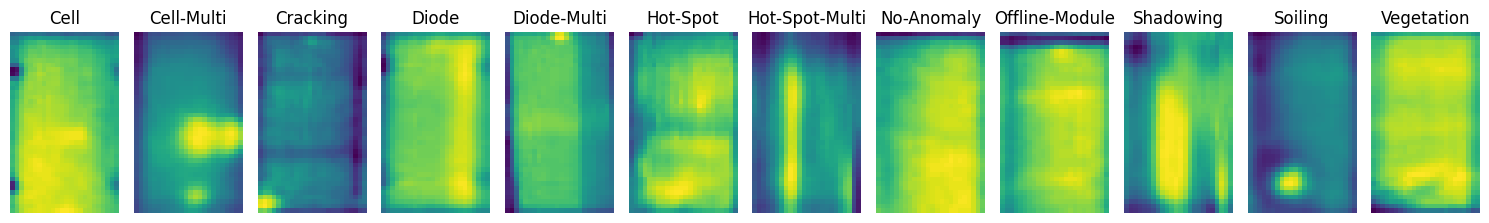

In [10]:
dataset_dir = "/kaggle/working/Solar_Dataset_Balanced_OS"
classes = sorted(os.listdir(dataset_dir))

plt.figure(figsize=(15, 3))
for i, c in enumerate(classes):
    cls_folder = os.path.join(dataset_dir, c)
    img_name = os.listdir(cls_folder)[0]
    p = os.path.join(cls_folder, img_name)
    
    plt.subplot(1, len(classes), i + 1)
    plt.imshow(Image.open(p))
    plt.title(c)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Bulding Baseline Model

In [31]:
def build_baseline_cnn(input_shape=(40, 24, 3), num_classes=12):
    inputs = layers.Input(shape=input_shape)
    
    # Block 1
    x = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(inputs)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)
    
    # Block 2
    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)
    
    # Block 3 (Baseline Conv Layer for Grad-CAM)
    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="last_conv_layer")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.4)(x)
    
    # Classification Head
    x = layers.Flatten()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    
    model1 = models.Model(inputs=inputs, outputs=outputs, name="Baseline_CNN")
    return model1

model1 = build_baseline_cnn()

model1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model1.summary()

Model: "Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 40, 24, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 40, 24, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 20, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 20, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 20, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 10, 6, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 10, 6, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv_layer (Conv2D)        │ (None, 10, 6, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 5, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 5, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1920)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │       122,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 216,972 (847.55 KB)

 Trainable params: 216,972 (847.55 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
# Callbacks and Training
my_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath="/kaggle/working/best_solar_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [33]:
history1 = model1.fit(
    train_data_aug,
    validation_data=val_data_norm,
    epochs=20,
    callbacks=my_callbacks,
)

Epoch 1/20
1497/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1071 - loss: 2.4557
Epoch 1: val_loss improved from None to 1.97826, saving model to /kaggle/working/best_solar_cnn.keras

Epoch 1: finished saving model to /kaggle/working/best_solar_cnn.keras
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 35s 19ms/step - accuracy: 0.1595 - loss: 2.3536 - val_accuracy: 0.3214 - val_loss: 1.9783 - learning_rate: 0.0010
Epoch 2/20
1498/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3094 - loss: 1.9813
Epoch 2: val_loss improved from 1.97826 to 1.66361, saving model to /kaggle/working/best_solar_cnn.keras

Epoch 2: finished saving model to /kaggle/working/best_solar_cnn.keras
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 29s 19ms/step - accuracy: 0.3352 - loss: 1.9075 - val_accuracy: 0.4254 - val_loss: 1.6636 - learning_rate: 0.0010
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3832 - loss: 1.7707
Epoch 3: val_loss improved from 1.66361 to 1.62849, saving model to /kaggle/working/best_sol

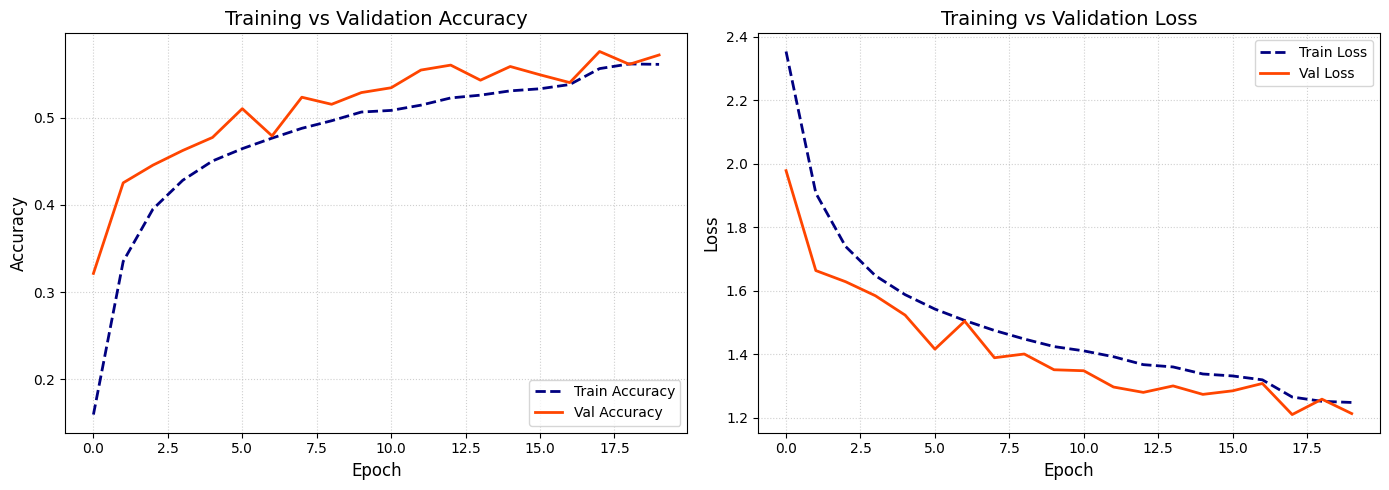

In [34]:
plt.figure(figsize=(14, 5))

# Accuracy Chart
plt.subplot(1, 2, 1)
plt.plot(history1.history['accuracy'], label='Train Accuracy', color='navy', linestyle='--', linewidth=2)
plt.plot(history1.history['val_accuracy'], label='Val Accuracy', color='orangered', linestyle='-', linewidth=2)
plt.title('Training vs Validation Accuracy', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

# Loss Chart
plt.subplot(1, 2, 2)
plt.plot(history1.history['loss'], label='Train Loss', color='navy', linestyle='--', linewidth=2)
plt.plot(history1.history['val_loss'], label='Val Loss', color='orangered', linestyle='-', linewidth=2)
plt.title('Training vs Validation Loss', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [35]:
test_loss1, test_acc1 = model1.evaluate(test_data_norm, verbose=0)
print(f"Test Loss: {test_loss1:.4f} | Test Accuracy: {test_acc1 * 100:.2f}%\n")

y_true1 = []
y_pred1 = []

for images, labels in test_data_norm:
    preds1 = model1.predict(images, verbose=0)
    y_true1.extend(np.argmax(labels.numpy(), axis=1))
    y_pred1.extend(np.argmax(preds1, axis=1))
    

y_true1 = np.array(y_true1)
y_pred1 = np.array(y_pred1)

Test Loss: 1.1791 | Test Accuracy: 59.18%



In [36]:
print("Detailed Classification Report:")
print(classification_report(y_true1, y_pred1, target_names=class_names, digits=3))

Detailed Classification Report:
                precision    recall  f1-score   support

          Cell      0.387     0.559     0.457      1038
    Cell-Multi      0.373     0.279     0.319      1016
      Cracking      0.745     0.567     0.644      1057
         Diode      0.798     0.831     0.814      1010
   Diode-Multi      0.931     0.811     0.867       977
      Hot-Spot      0.632     0.790     0.703       958
Hot-Spot-Multi      0.592     0.648     0.619       940
    No-Anomaly      0.434     0.725     0.543      1023
Offline-Module      0.514     0.675     0.583      1020
     Shadowing      0.687     0.572     0.624       996
       Soiling      0.718     0.365     0.484      1014
    Vegetation      0.650     0.297     0.408       983

      accuracy                          0.592     12032
     macro avg      0.622     0.593     0.589     12032
  weighted avg      0.621     0.592     0.587     12032



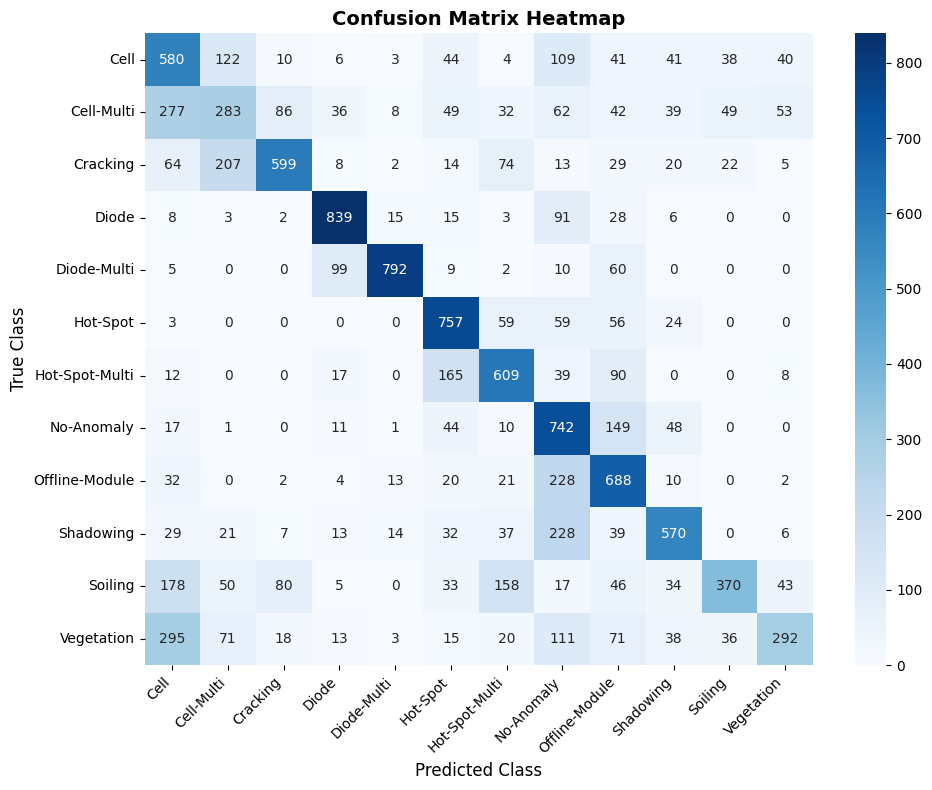

In [37]:
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_true1, y_pred1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix Heatmap', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12)
plt.ylabel('True Class', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Save Baseline CNN in Keras format
model1.save("/kaggle/working/baseline_solar_cnn.keras")

# Convert Baseline CNN to ONNX with the correct expected shape (40, 24, 3)
input_signature = [tf.TensorSpec(shape=(None, 40, 24, 3), dtype=tf.float32, name="input")]
onnx_model1, _ = tf2onnx.convert.from_keras(model, input_signature=input_signature, opset=15)

onnx.save(onnx_model1, "/kaggle/working/baseline_solar_cnn.onnx")

model1.save("/kaggle/working/baseline_solar_cnn.h5")

# Building Best Model

In [12]:
# Your Exact Custom CNN Architecture (Modified input_shape to 3 channels)
def build_cnn_model(input_shape=(40, 24, 3), num_classes=12):
    inputs = layers.Input(shape=input_shape)
    
    # Block 1
    x = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.2)(x)
    
    # Block 2
    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.3)(x)
    
    # Block 3: Keep spatial resolution for Grad-CAM
    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="last_conv_layer")(x)
    x = layers.BatchNormalization()(x)
    
    # Classification Head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    
    model = models.Model(inputs=inputs, outputs=outputs, name="Solar_Thermal_CNN")
    return model

model = build_cnn_model()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy", # Since we use One-Hot Encoding
    metrics=["accuracy"]
)

model.summary()

Model: "Solar_Thermal_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 40, 24, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 40, 24, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 40, 24, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 40, 24, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 40, 24, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 20, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 20, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 20, 12, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 20, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 20, 12, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 6, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 10, 6, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 10, 6, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 10, 6, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv_layer (Conv2D)        │ (None, 10, 6, 128)     │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 10, 6, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 306,860 (1.17 MB)

 Trainable params: 305,964 (1.17 MB)

 Non-trainable params: 896 (3.50 KB)

# Calbacks

In [13]:
# Callbacks and Training
my_callbacks 

# Training

In [14]:
history = model.fit(
    train_data_aug,
    validation_data=val_data_norm,
    epochs=35,
    callbacks=my_callbacks,
)

Epoch 1/35
   3/1500 ━━━━━━━━━━━━━━━━━━━━ 1:48 73ms/step - accuracy: 0.1094 - loss: 2.5200  

I0000 00:00:1792915685.789016     179 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step - accuracy: 0.4239 - loss: 1.6727
Epoch 1: val_loss improved from None to 2.07169, saving model to /kaggle/working/best_solar_cnn.keras

Epoch 1: finished saving model to /kaggle/working/best_solar_cnn.keras
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 459s 297ms/step - accuracy: 0.5273 - loss: 1.3663 - val_accuracy: 0.4109 - val_loss: 2.0717 - learning_rate: 0.0010
Epoch 2/35
1498/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6478 - loss: 0.9969
Epoch 2: val_loss improved from 2.07169 to 0.89063, saving model to /kaggle/working/best_solar_cnn.keras

Epoch 2: finished saving model to /kaggle/working/best_solar_cnn.keras
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 29s 19ms/step - accuracy: 0.6675 - loss: 0.9441 - val_accuracy: 0.6795 - val_loss: 0.8906 - learning_rate: 0.0010
Epoch 3/35
1499/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7179 - loss: 0.8124
Epoch 3: val_loss improved from 0.89063 to 0.87348, saving model to /kaggle/working/best_solar_cnn.k

# Train VS Validation 

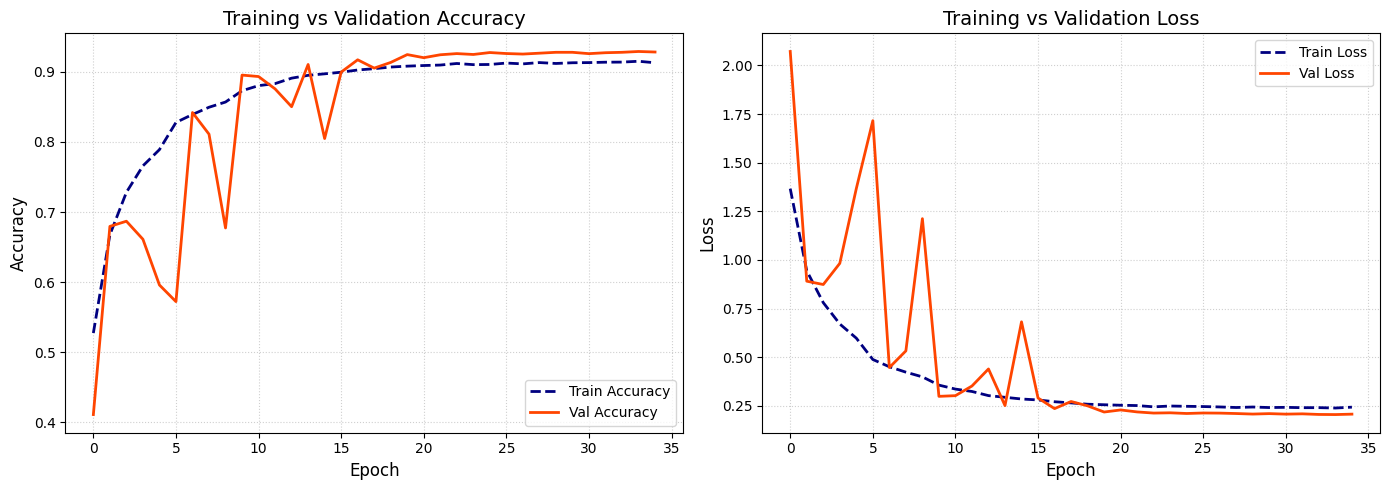

In [15]:
plt.figure(figsize=(14, 5))

# Accuracy Chart
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='navy', linestyle='--', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Val Accuracy', color='orangered', linestyle='-', linewidth=2)
plt.title('Training vs Validation Accuracy', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

# Loss Chart
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='navy', linestyle='--', linewidth=2)
plt.plot(history.history['val_loss'], label='Val Loss', color='orangered', linestyle='-', linewidth=2)
plt.title('Training vs Validation Loss', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Testing

In [16]:
test_loss, test_acc = model.evaluate(test_data_norm, verbose=0)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc * 100:.2f}%\n")

y_true = []
y_pred = []

for images, labels in test_data_norm:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))
    

y_true = np.array(y_true)
y_pred = np.array(y_pred)

Test Loss: 0.2008 | Test Accuracy: 92.90%



# Evaluation

In [18]:
accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')

print("="*40)
print(" OVERALL TEST METRICS (Weighted Average):")
print("="*40)
print(f"• Accuracy  : {accuracy * 100:.2f}%")
print(f"• Precision : {precision:.4f}")
print(f"• Recall    : {recall:.4f}")
print(f"• F1-Score  : {f1:.4f}")
print("="*40 + "\n")

 OVERALL TEST METRICS (Weighted Average):
• Accuracy  : 92.90%
• Precision : 0.9289
• Recall    : 0.9290
• F1-Score  : 0.9283



# Report

In [19]:
print("Detailed Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

Detailed Classification Report:
                precision    recall  f1-score   support

          Cell      0.791     0.827     0.808      1038
    Cell-Multi      0.860     0.719     0.783      1016
      Cracking      0.935     0.933     0.934      1057
         Diode      0.990     0.988     0.989      1010
   Diode-Multi      1.000     1.000     1.000       977
      Hot-Spot      0.991     1.000     0.995       958
Hot-Spot-Multi      0.983     1.000     0.992       940
    No-Anomaly      0.879     0.905     0.892      1023
Offline-Module      0.950     0.973     0.961      1020
     Shadowing      0.966     0.954     0.960       996
       Soiling      0.984     1.000     0.992      1014
    Vegetation      0.828     0.863     0.845       983

      accuracy                          0.929     12032
     macro avg      0.930     0.930     0.929     12032
  weighted avg      0.929     0.929     0.928     12032



# Confusion Matrix

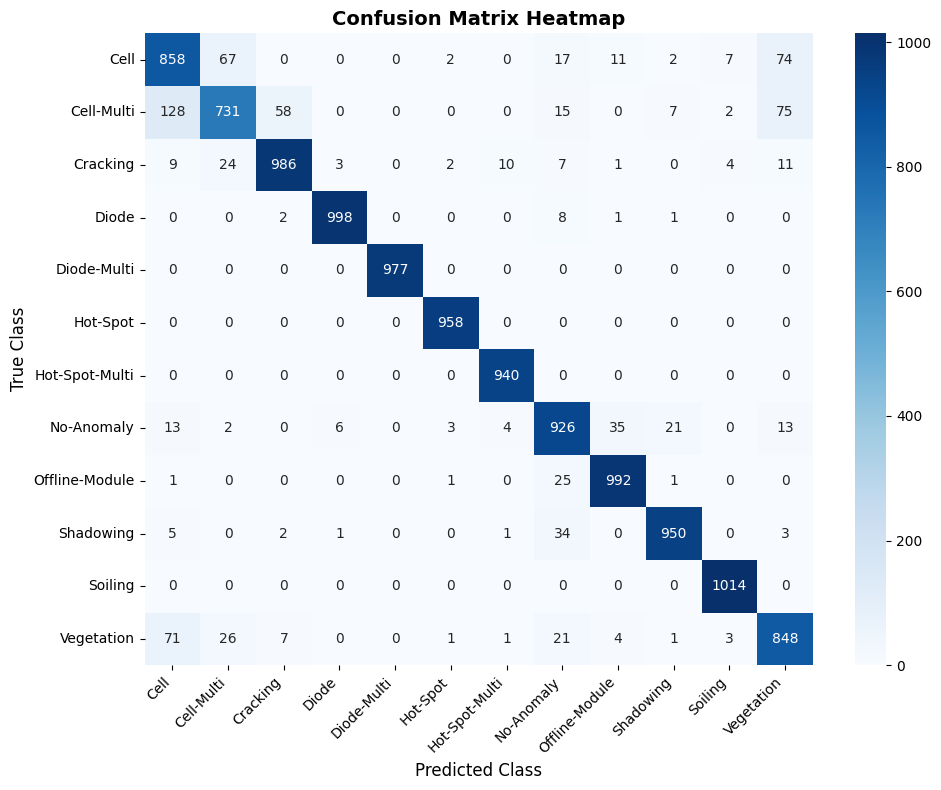

In [20]:
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix Heatmap', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12)
plt.ylabel('True Class', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Saving Model

In [ ]:
# Save Baseline CNN in Keras format
model.save("/kaggle/working/best_solar_cnn.keras")

# Convert Baseline CNN to ONNX with the correct expected shape (40, 24, 3)
input_signature = [tf.TensorSpec(shape=(None, 40, 24, 3), dtype=tf.float32, name="input")]
onnx_model, _ = tf2onnx.convert.from_keras(model, input_signature=input_signature, opset=15)

onnx.save(onnx_model, "/kaggle/working/best_solar_cnn.onnx")

model.save("/kaggle/working/best_solar_cnn.h5")

# Load JSON Mapping

In [23]:
# Load Model & JSON Mapping
model = tf.keras.models.load_model("/kaggle/working/best_solar_cnn.keras")
with open("/kaggle/input/datasets/ranaahmedelmaghraby/class-mapping/class_mapping.json") as f:
  data = json.load(f)

# Real Testing With Grad CAM

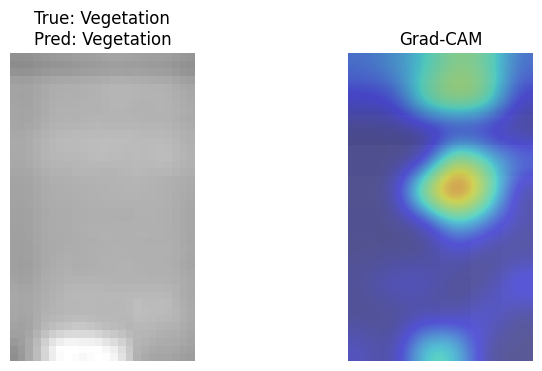

Pred: Vegetation (91.7%)
Level: Low | Action: Trim Vegetation / Clear Shading


In [24]:
# Get 1 Test Image
for images, labels in test_data_norm.take(1):
  img, true_idx = images[0], labels[0].numpy().argmax()
  img_tensor = tf.expand_dims(img, axis=0)

  # 1. Predict & Grad-CAM Setup
  preds = model.predict(img_tensor, verbose=0)
  pred_idx = preds.argmax()
  
  grad_model = tf.keras.models.Model(model.inputs,[model.get_layer("last_conv_layer").output, model.output],)

  # Compute Gradients using GradientTape
  with tf.GradientTape() as tape:
    conv_out, p = grad_model(img_tensor)
    loss = p[:, pred_idx]
    
  grads = tape.gradient(loss, conv_out)
  
  # Process Heatmap
  heatmap = tf.reduce_mean(grads, axis=(0, 1, 2))
  heatmap = tf.squeeze(tf.maximum(conv_out[0] @ heatmap[..., tf.newaxis], 0))
  
  max_val = tf.reduce_max(heatmap)
  if max_val > 0:
    heatmap /= max_val

  # 4. Show Plot & Report
  plt.figure(figsize=(8, 4))
  
  plt.subplot(1, 2, 1)
  plt.imshow(img)
  plt.title(f"True: {data['idx_to_class'][str(true_idx)]}\nPred: {data['idx_to_class'][str(pred_idx)]}")
  plt.axis("off")
  
  plt.subplot(1, 2, 2)
  plt.imshow(img)
  plt.imshow(heatmap.numpy(), cmap="jet", alpha=0.5, interpolation='bicubic')
  plt.title("Grad-CAM")
  plt.axis("off")
  plt.show()

    
  rec = data["priority_info"][data['idx_to_class'][str(pred_idx)]]
  print(f"Pred: {data['idx_to_class'][str(pred_idx)]} ({preds[0][pred_idx]*100:.1f}%)")
  print(f"Level: {rec['level']} | Action: {rec['action']}")
  break